# Campbell m.fl. (2010) – ryddet version
Delspørgsmål 2: dollarens afdækningsegenskaber (optimal hedge ratio) før og efter april 2025.
Samme brud, samme valutakurs (USD/EUR, + = dollaren styrkes) og samme tabelformat som LP-notebooken.
Rækkefølge: 0 imports → 1 data → 2 afkast → 3 figur 6.1 → 4 funktioner
            → 5 hovedtabel (brud) → 6 betinget model (TPU/GPR) → 7 robusthed → 8 optimal vs. faktisk

### 0) Imports

In [10]:
import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import norm

os.makedirs("TABLES", exist_ok=True)
os.makedirs("FIGURES", exist_ok=True)

### 1) Indlæs masterdatasættet (KUN her)

In [11]:
BASE = "/Users/PC/Documents/Speciale/Analyse/Speciale"
master = pd.read_csv(os.path.join(BASE, "clean", "master_monthly.csv"))
master["month"] = pd.to_datetime(master["month"])
master = master.sort_values("month").reset_index(drop=True)

# Brud: samme definition som i LP-notebooken
master["post_LD"] = (master["month"] >= pd.Timestamp("2025-04-30")).astype(int)

def stjerner(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def _stj(p):          # til LaTeX
    return "^{***}" if p < 0.01 else "^{**}" if p < 0.05 else "^{*}" if p < 0.10 else ""

### 2) Afkast (Campbell m.fl. 2010, lign. 1 og 4)

In [12]:
# Bloomberg-data bruges, hvis kolonnerne findes i master; ellers CRSP (slutter dec. 2025).
# Når SPXT og LUATTRUU er lagt ind i master (som indeksniveauer), skifter koden automatisk.
BRUG_BLOOMBERG = {"SPXT", "LUATTRUU"}.issubset(master.columns)
print("Datakilde:", "Bloomberg (SPXT, LUATTRUU)" if BRUG_BLOOMBERG else "CRSP (vwretd, bond_ret)")

# Risikofri renter: årlig pct. -> månedlig sats
master["r_us_m"]  = master["USD OIS 3m"] / 100 / 12
master["r_eur_m"] = master["EUR OIS 3m"] / 100 / 12

# Dollarens afkast over for euroen (EUR pr. USD), + = dollaren styrkes
master["usd_eur_ret"] = (1 / master["EURUSD"]).pct_change()
master["usd_eur_x"]   = master["usd_eur_ret"] + (master["r_us_m"] - master["r_eur_m"])
master["usd_eur_qx"]  = np.log(1 + master["usd_eur_x"]).rolling(3).sum()

def lav_afkast(navn, ret):
    """Månedligt merafkast (navn_x) og overlappende kvartalsvist log-merafkast (navn_qx)."""
    master[f"{navn}_x"]  = ret - master["r_us_m"]
    master[f"{navn}_qx"] = np.log(1 + master[f"{navn}_x"]).rolling(3).sum()

# Baseline: amerikanske aktier og statsobligationer
if BRUG_BLOOMBERG:
    lav_afkast("aktie", master["SPXT"].pct_change())
    lav_afkast("obl",   master["LUATTRUU"].pct_change())
else:
    lav_afkast("aktie", master["vwretd"])
    lav_afkast("obl",   master["bond_ret"])

# Robusthed: CRSP og globale indeks (MSCI World net return, Bloomberg Global Treasury)
lav_afkast("aktie_crsp", master["vwretd"])
lav_afkast("obl_crsp",   master["bond_ret"])
lav_afkast("aktie_glob", master["NDDUWI"].pct_change())
lav_afkast("obl_glob",   master["LGTRTRUU"].pct_change())

# Usikkerhedsindeks: standardiseret log (samme som LP) + 3 mdr. lag (forudbestemt)
for navn, kol in [("TPU", "TPU"), ("GPR", "GPR"), ("GPR_USA", "GPRC_USA")]:
    master[f"ln{navn}_z"]     = np.log(master[kol]).pipe(lambda s: (s - s.mean()) / s.std())
    master[f"ln{navn}_z_lag"] = master[f"ln{navn}_z"].shift(3)

# Datatjek: sidste måned med data
kol = ["EURUSD", "USD OIS 3m", "EUR OIS 3m", "usd_eur_qx", "aktie_qx", "obl_qx",
       "aktie_crsp_qx", "aktie_glob_qx", "obl_glob_qx", "USD_hedge_ratio"]
print(pd.Series({c: master.loc[master[c].notna(), "month"].max().date() for c in kol},
                name="sidste måned med data").to_string())

Datakilde: CRSP (vwretd, bond_ret)
EURUSD             2026-07-31
USD OIS 3m         2026-07-31
EUR OIS 3m         2026-07-31
usd_eur_qx         2026-07-31
aktie_qx           2025-12-31
obl_qx             2025-12-31
aktie_crsp_qx      2025-12-31
aktie_glob_qx      2026-07-31
obl_glob_qx        2026-07-31
USD_hedge_ratio    2026-07-31


### 3) Figur 6.1: USD/EUR og begivenheder

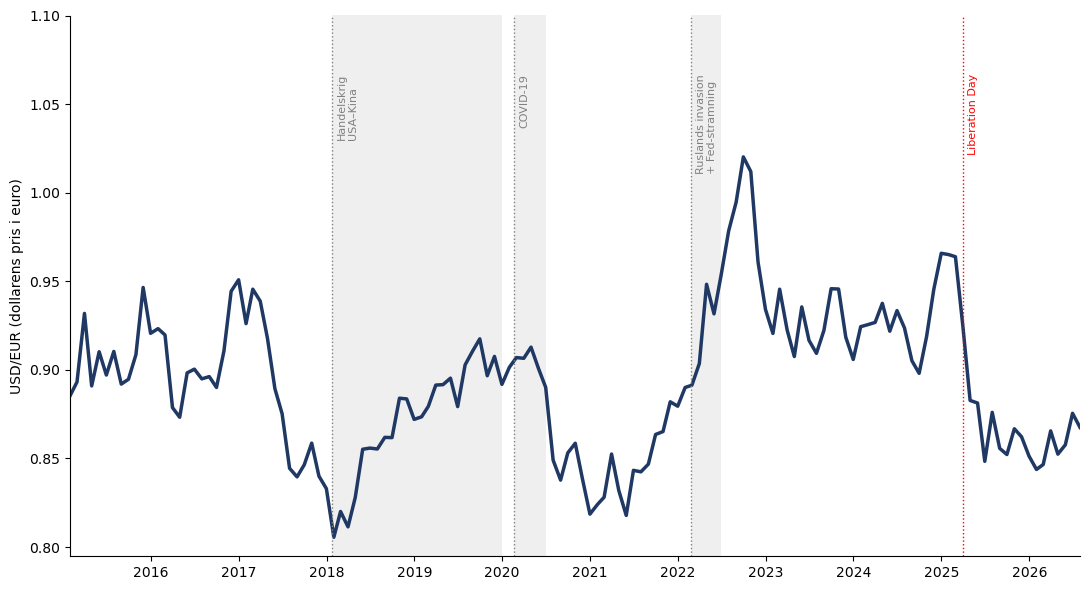

In [13]:
master["usd_eur_level"] = 1 / master["EURUSD"]
d = master.dropna(subset=["usd_eur_level"])

spans = [  # (start, slut, tekst) – handelskrigen starter med de første toldsatser 22/1-2018
    ("2018-01-22", "2019-12-31", "Handelskrig\nUSA–Kina"),
    ("2020-02-20", "2020-06-30", "COVID-19"),
    ("2022-02-24", "2022-06-30", "Ruslands invasion\n+ Fed-stramning"),
]
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(d["month"], d["usd_eur_level"], color="#1f3864", lw=2.5)
ax.set_ylabel("USD/EUR (dollarens pris i euro)")
ax.set_xlim(d["month"].min(), d["month"].max())
ax.set_ylim(top=1.10)
ymax, offset = ax.get_ylim()[1], pd.Timedelta(days=20)
for start, slut, tekst in spans:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(slut), color="gray", alpha=0.12, lw=0)
    ax.axvline(pd.Timestamp(start), color="gray", lw=1, ls=":")
    ax.text(pd.Timestamp(start) + offset, ymax * 0.97, tekst, color="gray", fontsize=8,
            rotation=90, va="top", ha="left")
ld = pd.Timestamp("2025-04-02")
ax.axvline(ld, color="red", lw=1, ls=":")
ax.text(ld + offset, ymax * 0.97, "Liberation Day", color="red", fontsize=8,
        rotation=90, va="top", ha="left")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("FIGURES/USDEUR_PLOT.pdf", bbox_inches="tight")
plt.savefig("FIGURES/USDEUR_PLOT.png", dpi=300, bbox_inches="tight")
plt.show()

### 4) FUNKTIONER

In [14]:
def campbell_fit(y, fx, data, brud=None, z=None, se="hac", maxlags=6):
    """OLS af aktivets merafkast på dollarens merafkast (evt. interageret med brud eller z).
    se='hac': Newey-West (overlappende kvartalsafkast, jf. Campbell m.fl. 2010, tabel III)
    se='hc3': HC3 (månedsafkast uden overlap)"""
    ekstra = [v for v in (brud, z) if v is not None]
    d = data.dropna(subset=[y, fx] + ekstra).copy()
    formel = f"{y} ~ {fx}" + "".join(f" * {v}" for v in ekstra)
    mod = smf.ols(formel, data=d)
    m = (mod.fit(cov_type="HAC", cov_kwds={"maxlags": maxlags}) if se == "hac"
         else mod.fit(cov_type="HC3"))
    return m, d


def campbell_brud(y, fx="usd_eur_qx", data=None, brud="post_LD", se="hac", maxlags=6,
                  pre_slut="2024-12-31"):
    """Optimal hedge ratio h* = 1 + beta (Campbell m.fl. 2010) – samme opbygning som LP-tabel 1.
    p-værdierne for h* tester H0: h* = 1 (beta = 0), dvs. at dollaren ingen afdækningsværdi har."""
    data = master if data is None else data
    m1, _ = campbell_fit(y, fx, data, se=se, maxlags=maxlags)
    m2, _ = campbell_fit(y, fx, data[data["month"] <= pd.Timestamp(pre_slut)], se=se, maxlags=maxlags)
    m, d  = campbell_fit(y, fx, data, brud=brud, se=se, maxlags=maxlags)
    inter = f"{fx}:{brud}"
    V = m.cov_params()
    h_efter  = 1 + m.params[fx] + m.params[inter]
    se_efter = np.sqrt(V.loc[fx, fx] + V.loc[inter, inter] + 2 * V.loc[fx, inter])
    return {"h_fuld":  1 + m1.params[fx], "se_fuld":  m1.bse[fx], "p_fuld": m1.pvalues[fx],
            "h_foer":  1 + m2.params[fx], "se_foer":  m2.bse[fx], "p_foer": m2.pvalues[fx],
            "h_efter": h_efter, "se_efter": se_efter,
            "p_efter": 2 * (1 - norm.cdf(abs((h_efter - 1) / se_efter))),
            "forskel": m.params[inter], "se_forskel": m.bse[inter], "p_forskel": m.pvalues[inter],
            "n_post": int(d[brud].sum()), "n": int(m.nobs)}


def i_episode(maaned, start, slut, forlaeng=2):
    """Kvartalsafkast i måned t dækker t-2..t -> forlæng episoden med 2 mdr."""
    s, e = pd.Timestamp(start), pd.Timestamp(slut) + pd.offsets.MonthEnd(forlaeng)
    return (maaned >= s) & (maaned <= e)

HANDELSKRIG = ("2018-01-31", "2019-12-31")   # samme datoer som EPISODER_TPU_LP i LP-notebooken

### 5) HOVEDTABEL: optimal hedge ratio før og efter april 2025

In [15]:
# %% 5) HOVEDTABEL: optimal hedge ratio før og efter april 2025
AKTIVER = [("Aktier", "aktie"), ("Obligationer", "obl")]
PANELER = [("Panel A: Kvartalsafkast (baseline)", "_qx", "usd_eur_qx", "hac"),
           ("Panel B: Månedsafkast",              "_x",  "usd_eur_x",  "hc3")]

brud_res = {}
for ptitel, suf, fx, se in PANELER:
    for navn, a in AKTIVER:
        brud_res[(ptitel, navn)] = campbell_brud(f"{a}{suf}", fx=fx, se=se)

vis = pd.DataFrame(brud_res).T
print(vis[["h_fuld", "p_fuld", "h_foer", "p_foer", "h_efter", "p_efter",
           "forskel", "p_forskel", "n_post"]].round(3))

def _c(x, se, p):
    return f"${x:.2f}{_stj(p)}$", f"$({se:.2f})$"

linjer = []
for i, (ptitel, suf, fx, se) in enumerate(PANELER):
    if i > 0:
        linjer.append(r"\addlinespace")
    linjer.append(rf"\multicolumn{{6}}{{l}}{{\textit{{{ptitel}}}}} \\")
    for navn, _ in AKTIVER:
        r = brud_res[(ptitel, navn)]
        c1 = _c(r["h_fuld"],  r["se_fuld"],    r["p_fuld"])
        c2 = _c(r["h_foer"],  r["se_foer"],    r["p_foer"])
        c3 = _c(r["h_efter"], r["se_efter"],   r["p_efter"])
        c4 = _c(r["forskel"], r["se_forskel"], r["p_forskel"])
        linjer.append(f"{navn} & {c1[0]} & {c2[0]} & {c3[0]} & {c4[0]} & {r['n_post']} \\\\")
        linjer.append(f" & {c1[1]} & {c2[1]} & {c3[1]} & {c4[1]} & \\\\[2pt]")

NOTE_CB = (r"Optimal hedge ratio $h^* = 1 + \beta$, hvor $\beta$ er koefficienten fra en regression "
           r"af merafkastet på amerikanske aktier og statsobligationer på dollarens merafkast over for "
           r"euroen (Campbell m.fl., 2010). (1) Hele stikprøven. (2) Stikprøve til og med december 2024. "
           r"(3) $h^*$ efter april 2025, $1+\beta+\phi$, fra en model med brud-dummy. (4) Forskellen "
           r"$\phi$. Standardfejl i parentes: Newey-West med 6 lags i panel A (overlappende "
           r"kvartalsafkast) og HC3 i panel B. Stjerner ved $h^*$ angiver, at $h^*$ er signifikant "
           r"forskellig fra 1. Det svarer til Campbell m.fl.'s (2010) test af, at den optimale "
           r"dollareksponering, $1-h^*$, er nul. Stjerner ved forskellen angiver, at $h^*$ har ændret "
           r"sig. $^{*}$, $^{**}$ og $^{***}$ angiver signifikans på 10, 5 og 1 pct.-niveau. "
           r"$n_{\text{post}}$ er antallet af månedlige observationer efter bruddet; i panel A "
           r"overlapper kvartalsafkastene, så antallet af uafhængige kvartaler er ca. en tredjedel.")

tex = (r"""\begin{table}[H]
\centering
\caption{Optimal hedge ratio for amerikanske aktiver før og efter april 2025}
\label{tab:campbell_brud}
\begin{threeparttable}
\begin{tabular}{l cccc c}
\toprule
 & (1) & (2) & (3) & (4) & \\
 & Hele perioden & Før 2025 & Efter april 2025 & Forskel & $n_{\text{post}}$ \\
\midrule
""" + "\n".join(linjer) + r"""
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]\footnotesize
\item \textit{Note:} """ + NOTE_CB + r"""
\end{tablenotes}
\end{threeparttable}
\end{table}""")
with open("TABLES/campbell_brud.tex", "w", encoding="utf-8") as f:
    f.write(tex)
print("Gemt: TABLES/campbell_brud.tex")

                                                 h_fuld  p_fuld  h_foer  \
Panel A: Kvartalsafkast (baseline) Aktier         0.415   0.023   0.239   
                                   Obligationer   0.715   0.001   0.696   
Panel B: Månedsafkast              Aktier         0.467   0.004   0.343   
                                   Obligationer   0.749   0.000   0.741   

                                                 p_foer  h_efter  p_efter  \
Panel A: Kvartalsafkast (baseline) Aktier         0.002    1.747    0.028   
                                   Obligationer   0.001    0.920    0.083   
Panel B: Månedsafkast              Aktier         0.001    1.071    0.858   
                                   Obligationer   0.000    0.766    0.001   

                                                 forskel  p_forskel  n_post  
Panel A: Kvartalsafkast (baseline) Aktier          1.459      0.000     9.0  
                                   Obligationer    0.225      0.027     9.0  
Pane

### 6) BETINGET MODEL: afhænger afdækningsværdien af usikkerheden?

In [16]:
# delta = interaktionsleddet mellem dollarens afkast og usikkerhedsindekset.
# Estimeres over hele perioden og før 2025 for at vise, om delta er drevet af 2025.
Z_SUFFIX = "_z"            # "_z" = samtidig, "_z_lag" = lagget 3 mdr. (forudbestemt, Campbell lign. 4)
INDEKS = [("TPU", "TPU"), ("GPR", "GPR"), ("GPR_USA", r"$\text{GPR}_{\text{USA}}$")]
PERIODER = [("Hele perioden", None), ("Før 2025", "2024-12-31")]

bet = {}
for navn, a in AKTIVER:
    for idx, _ in INDEKS:
        for ptekst, slut in PERIODER:
            data = master if slut is None else master[master["month"] <= pd.Timestamp(slut)]
            z = f"ln{idx}{Z_SUFFIX}"
            m, _ = campbell_fit(f"{a}_qx", "usd_eur_qx", data, z=z)
            inter = f"usd_eur_qx:{z}"
            bet[(navn, idx, ptekst)] = (m.params[inter], m.bse[inter], m.pvalues[inter], int(m.nobs))
            print(f"{navn:12s} {idx:8s} {ptekst:14s} delta = {m.params[inter]: .3f}"
                  f"{stjerner(m.pvalues[inter]):3s} (p = {m.pvalues[inter]:.3f}), N = {int(m.nobs)}")

linjer = []
for idx, idx_tex in INDEKS:
    celler, se_celler = [], []
    for navn, _ in AKTIVER:
        for ptekst, _ in PERIODER:
            b, s, p, n = bet[(navn, idx, ptekst)]
            celler.append(f"${b:.2f}{_stj(p)}$"); se_celler.append(f"$({s:.2f})$")
    linjer.append(f"{idx_tex} & " + " & ".join(celler) + r" \\")
    linjer.append(" & " + " & ".join(se_celler) + r" \\[2pt]")

tex = (r"""\begin{table}[H]
\centering
\caption{Dollarens afdækningsværdi og usikkerhed: interaktionsleddet $\delta$}
\label{tab:campbell_betinget}
\begin{threeparttable}
\begin{tabular}{l cc cc}
\toprule
 & \multicolumn{2}{c}{Aktier} & \multicolumn{2}{c}{Obligationer} \\
\cmidrule(lr){2-3}\cmidrule(lr){4-5}
 & Hele perioden & Før 2025 & Hele perioden & Før 2025 \\
\midrule
""" + "\n".join(linjer) + r"""
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]\footnotesize
\item \textit{Note:} Koefficienten $\delta$ på interaktionsleddet mellem dollarens merafkast og det
standardiserede log-usikkerhedsindeks i en regression af aktivets kvartalsvise merafkast, så
$h^*(z) = 1 + \beta + \delta z$. Et positivt $\delta$ betyder, at den optimale hedge ratio stiger med
usikkerheden. Newey-West-standardfejl med 6 lags i parentes. $^{*}$, $^{**}$ og $^{***}$ angiver
signifikans på 10, 5 og 1 pct.-niveau.
\end{tablenotes}
\end{threeparttable}
\end{table}""")
with open("TABLES/campbell_betinget.tex", "w", encoding="utf-8") as f:
    f.write(tex)
print("Gemt: TABLES/campbell_betinget.tex")

Aktier       TPU      Hele perioden  delta =  0.392*** (p = 0.005), N = 129
Aktier       TPU      Før 2025       delta = -0.066    (p = 0.838), N = 117
Aktier       GPR      Hele perioden  delta =  0.121    (p = 0.545), N = 129
Aktier       GPR      Før 2025       delta =  0.092    (p = 0.732), N = 117
Aktier       GPR_USA  Hele perioden  delta =  0.164    (p = 0.445), N = 129
Aktier       GPR_USA  Før 2025       delta =  0.115    (p = 0.692), N = 117
Obligationer TPU      Hele perioden  delta =  0.069    (p = 0.223), N = 129
Obligationer TPU      Før 2025       delta = -0.039    (p = 0.777), N = 117
Obligationer GPR      Hele perioden  delta = -0.216*** (p = 0.005), N = 129
Obligationer GPR      Før 2025       delta = -0.330*** (p = 0.000), N = 117
Obligationer GPR_USA  Hele perioden  delta = -0.202**  (p = 0.018), N = 129
Obligationer GPR_USA  Før 2025       delta = -0.336*** (p = 0.000), N = 117
Gemt: TABLES/campbell_betinget.tex


### 7) ROBUSTHED: bruddet i den optimale hedge ratio

In [17]:
uden_hk = master[~i_episode(master["month"], *HANDELSKRIG)]

ROB = {  # navn: (aktie-kolonne, obligations-kolonne, fx, se, maxlags, data)
    "Baseline (kvartal, NW 6)":       ("aktie_qx",      "obl_qx",      "usd_eur_qx", "hac", 6, master),
    "Newey-West, 3 lags":             ("aktie_qx",      "obl_qx",      "usd_eur_qx", "hac", 3, master),
    "Månedsafkast (HC3)":             ("aktie_x",       "obl_x",       "usd_eur_x",  "hc3", 0, master),
    "Globale indeks":                 ("aktie_glob_qx", "obl_glob_qx", "usd_eur_qx", "hac", 6, master),
    "Uden handelskrigen 2018--19":    ("aktie_qx",      "obl_qx",      "usd_eur_qx", "hac", 6, uden_hk),
}
if BRUG_BLOOMBERG:   # CRSP som robusthed, når baseline er Bloomberg
    ROB["CRSP-data (til dec. 2025)"] = ("aktie_crsp_qx", "obl_crsp_qx", "usd_eur_qx", "hac", 6, master)

linjer, rob_vis = [], {}
for navn, (ya, yo, fx, se, ml, data) in ROB.items():
    celler = []
    for y in (ya, yo):
        r = campbell_brud(y, fx=fx, data=data, se=se, maxlags=max(ml, 1))
        rob_vis[(navn, y)] = r
        celler += [f"${r['h_foer']:.2f}$", f"${r['h_efter']:.2f}$",
                   f"${r['forskel']:.2f}{_stj(r['p_forskel'])}$"]
    linjer.append(f"{navn} & " + " & ".join(celler) + r" \\")

print(pd.DataFrame(rob_vis).T[["h_foer", "h_efter", "forskel", "p_forskel", "n_post"]].round(3))

tex = (r"""\begin{table}[H]
\centering
\caption{Robusthed: optimal hedge ratio før og efter april 2025}
\label{tab:campbell_rob}
\begin{threeparttable}
\begin{tabular}{l ccc ccc}
\toprule
 & \multicolumn{3}{c}{Aktier} & \multicolumn{3}{c}{Obligationer} \\
\cmidrule(lr){2-4}\cmidrule(lr){5-7}
Specifikation & Før 2025 & Efter & Forskel & Før 2025 & Efter & Forskel \\
\midrule
""" + "\n".join(linjer) + r"""
\bottomrule
\end{tabular}
\begin{tablenotes}[flushleft]\footnotesize
\item \textit{Note:} Optimal hedge ratio $h^* = 1+\beta$ før 2025 (stikprøve til og med december 2024)
og efter april 2025 samt forskellen $\phi$, jf. tabel \ref{tab:campbell_brud}. Hver række ændrer én ting
i forhold til baseline. Globale indeks: MSCI World (net return) og Bloomberg Global Treasury, begge i USD.
Stjerner angiver signifikans af forskellen: $^{*}$, $^{**}$ og $^{***}$ på 10, 5 og 1 pct.-niveau.
\end{tablenotes}
\end{threeparttable}
\end{table}""")
with open("TABLES/campbell_rob.tex", "w", encoding="utf-8") as f:
    f.write(tex)
print("Gemt: TABLES/campbell_rob.tex")

                                           h_foer  h_efter  forskel  \
Baseline (kvartal, NW 6)    aktie_qx        0.239    1.747    1.459   
                            obl_qx          0.696    0.920    0.225   
Newey-West, 3 lags          aktie_qx        0.239    1.747    1.459   
                            obl_qx          0.696    0.920    0.225   
Månedsafkast (HC3)          aktie_x         0.343    1.071    0.652   
                            obl_x           0.741    0.766    0.019   
Globale indeks              aktie_glob_qx   0.112    1.251    1.092   
                            obl_glob_qx     0.198    0.457    0.248   
Uden handelskrigen 2018--19 aktie_qx        0.201    1.747    1.489   
                            obl_qx          0.598    0.920    0.319   

                                           p_forskel  n_post  
Baseline (kvartal, NW 6)    aktie_qx           0.000     9.0  
                            obl_qx             0.027     9.0  
Newey-West, 3 lags          a

### 8) Optimal vs. faktisk afdækning over tid (til afsnit 6.3)

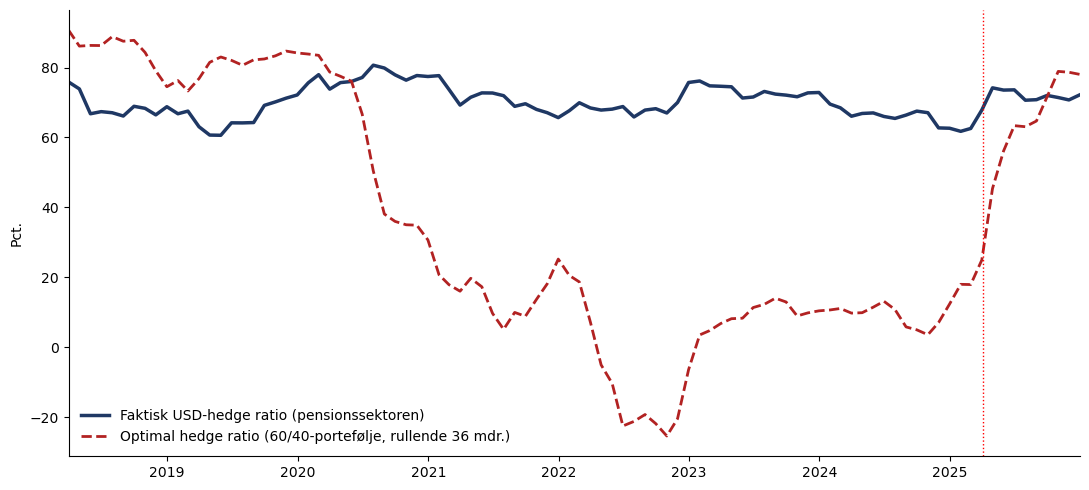

Implicit risikoaversion før 2025: median = 4.9


In [18]:
W_AKTIER = 0.6        # antaget aktieandel af dollareksponeringen
VINDUE   = 36         # rullende vindue i måneder

master["port_qx"] = W_AKTIER * master["aktie_qx"] + (1 - W_AKTIER) * master["obl_qx"]
beta_rul = (master["port_qx"].rolling(VINDUE).cov(master["usd_eur_qx"])
            / master["usd_eur_qx"].rolling(VINDUE).var())
master["h_opt"]     = 100 * (1 + beta_rul)
master["h_faktisk"] = 100 * master["USD_hedge_ratio"]

d = master.dropna(subset=["h_opt", "h_faktisk"])
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(d["month"], d["h_faktisk"], color="#1f3864", lw=2.5,
        label="Faktisk USD-hedge ratio (pensionssektoren)")
ax.plot(d["month"], d["h_opt"], color="#b22222", lw=2, ls="--",
        label=f"Optimal hedge ratio ({int(W_AKTIER*100)}/{int((1-W_AKTIER)*100)}-portefølje, "
              f"rullende {VINDUE} mdr.)")
ax.axvline(pd.Timestamp("2025-04-02"), color="red", lw=1, ls=":")
ax.set_ylabel("Pct.")
ax.set_xlim(d["month"].min(), d["month"].max())
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig("FIGURES/optimal_vs_faktisk.pdf", bbox_inches="tight")
plt.show()

# Implicit risikoaversion, der kan forklare kløften (Solvency II)
C_KAPITAL = 0.06     # kapitalomkostning pr. år (tjek aktuel sats)
KAPPA     = 0.25     # kapitalkrav på uafdækket ikke-euro-valuta (Grønlund m.fl. 2024)
var_q  = master["usd_eur_qx"].rolling(VINDUE).var()
kloeft = (master["h_faktisk"] - master["h_opt"]) / 100
master["A_impl"] = (C_KAPITAL * KAPPA / 4) / (var_q * kloeft)
foer25 = master[(master["month"] <= "2024-12-31") & (kloeft > 0)]
print(f"Implicit risikoaversion før 2025: median = {foer25['A_impl'].median():.1f}")